In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

today = datetime.now()

employees_data = [
    {"Таб. номер": 101, "Фамилия": "Иванов И.И.", "Дата поступления": "2015-03-10", "Дата рождения": "1985-06-15", "Оклад": 50000},
    {"Таб. номер": 102, "Фамилия": "Петров П.П.", "Дата поступления": "2018-07-01", "Дата рождения": "1992-11-20", "Оклад": 60000},
    {"Таб. номер": 103, "Фамилия": "Сидоров С.С.", "Дата поступления": "2020-01-15", "Дата рождения": "1995-02-10", "Оклад": 45000},
    {"Таб. номер": 104, "Фамилия": "Кузнецова А.А.", "Дата поступления": "2012-09-01", "Дата рождения": "1980-05-05", "Оклад": 80000},
    {"Таб. номер": 105, "Фамилия": "Смирнов Д.Д.", "Дата поступления": "2021-10-10", "Дата рождения": "2000-08-25", "Оклад": 40000},
    {"Таб. номер": 106, "Фамилия": "Волкова Е.Е.", "Дата поступления": "2019-03-20", "Дата рождения": "1998-12-01", "Оклад": 55000},
    {"Таб. номер": 107, "Фамилия": "Морозов М.М.", "Дата поступления": "2010-05-05", "Дата рождения": "1975-03-30", "Оклад": 90000},
    {"Таб. номер": 108, "Фамилия": "Новикова Н.Н.", "Дата поступления": "2022-02-01", "Дата рождения": "2001-07-07", "Оклад": 35000}
]

df = pd.DataFrame(employees_data)

df["Дата поступления"] = pd.to_datetime(df["Дата поступления"])
df["Дата рождения"] = pd.to_datetime(df["Дата рождения"])

print("Исходная таблица:")
display(df)

Исходная таблица:


,Таб. номер,Фамилия,Дата поступления,Дата рождения,Оклад
0,101,Иванов И.И.,2015-03-10,1985-06-15,50000
1,102,Петров П.П.,2018-07-01,1992-11-20,60000
2,103,Сидоров С.С.,2020-01-15,1995-02-10,45000
3,104,Кузнецова А.А.,2012-09-01,1980-05-05,80000
4,105,Смирнов Д.Д.,2021-10-10,2000-08-25,40000
5,106,Волкова Е.Е.,2019-03-20,1998-12-01,55000
6,107,Морозов М.М.,2010-05-05,1975-03-30,90000
7,108,Новикова Н.Н.,2022-02-01,2001-07-07,35000


In [3]:
def calculate_age(born):
    return today.year - born.year - ((today.month, today.day) < (born.month, born.day))

def calculate_experience(hired):
    return today.year - hired.year - ((today.month, today.day) < (hired.month, hired.day))

df["Возраст"] = df["Дата рождения"].apply(calculate_age)
df["Стаж"] = df["Дата поступления"].apply(calculate_experience)

print("Таблица с расчетами:")
display(df)

Таблица с расчетами:


,Таб. номер,Фамилия,Дата поступления,Дата рождения,Оклад,Возраст,Стаж
0,101,Иванов И.И.,2015-03-10,1985-06-15,50000,41,11
1,102,Петров П.П.,2018-07-01,1992-11-20,60000,33,8
2,103,Сидоров С.С.,2020-01-15,1995-02-10,45000,31,6
3,104,Кузнецова А.А.,2012-09-01,1980-05-05,80000,46,14
4,105,Смирнов Д.Д.,2021-10-10,2000-08-25,40000,26,5
5,106,Волкова Е.Е.,2019-03-20,1998-12-01,55000,27,7
6,107,Морозов М.М.,2010-05-05,1975-03-30,90000,51,16
7,108,Новикова Н.Н.,2022-02-01,2001-07-07,35000,25,4


In [4]:
def get_employee_info(tab_num):
    employee = df[df["Таб. номер"] == tab_num]

    if not employee.empty:
        print(f"--- Данные по сотруднику с табельным номером {tab_num} ---")
        print(employee.T)
    else:
        print(f"Сотрудник с номером {tab_num} не найден.")

get_employee_info(104)

--- Данные по сотруднику с табельным номером 104 ---
                                    3
Таб. номер                        104
Фамилия                Кузнецова А.А.
Дата поступления  2012-09-01 00:00:00
Дата рождения     1980-05-05 00:00:00
Оклад                           80000
Возраст                            46
Стаж                               14


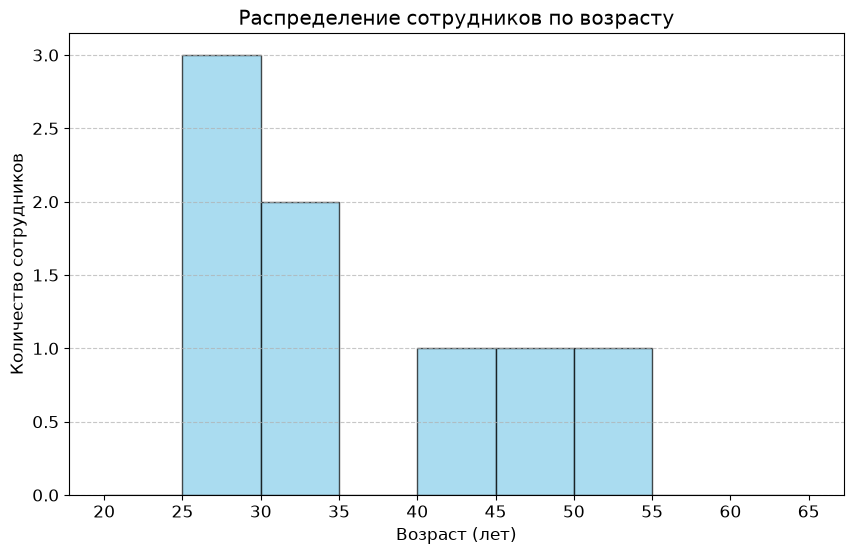

In [5]:
plt.rcParams['font.size'] = 12

plt.figure(figsize=(10, 6))
plt.hist(df["Возраст"], bins=range(20, 70, 5), edgecolor='black', alpha=0.7, color='skyblue')

plt.title("Распределение сотрудников по возрасту")
plt.xlabel("Возраст (лет)")
plt.ylabel("Количество сотрудников")
plt.xticks(range(20, 70, 5))
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()